<table style="width: 100%; margin-left: auto; margin-right: auto; background-color: white;">
<tbody>
<tr>

<td style="text-align: center; width: 12%;"><img src=img/brasil-brasao.png alt="" /></td>

<td style="width: 68%;">
<h2 style="text-align: center; margin-top: 1%;">Rep&uacute;blica Federativa do Brasil</h2>
<h2 style="text-align: center; margin-top: 1%;">Minist&eacute;rio da Educa&ccedil;&atilde;o</h2>
<h2 style="text-align: center; margin-top: 1%;">Universidade Federal do Amazonas</h2>
<h2 style="text-align: center; margin-top: 1%;">Instituto de Computa&ccedil;&atilde;o</h2>
</td>

<td style="width: 12%;"><img src="img/UFAM-logo.png" alt="" /></td>

</tr>
</tbody>
</table>

---

# Ciência de Dados
## Trabalho Prático I: Exploração de Dados

_Professor Dr. Marco Cristo_

**Alunos:**  `Sarah Lima, Nome Sobrenome e Nome Sobrenome` <br>
**E-mail:** `sarah.lima@icomp.ufam.edu.br, nome.sobrenome@icomp.ufam.edu.br e nome.sobrenome@icomp.ufam.edu.br`

#### Preliminares

In [345]:
# Imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

import sklearn
import sys
import os 

In [346]:
print("Python", sys.version)
print("--------")
print("Pandas:", pd.__version__)
print("Numpy:", np.__version__)
print("SKLearn:", sklearn.__version__)

Python 3.13.3 (tags/v3.13.3:6280bb5, Apr  8 2025, 14:47:33) [MSC v.1943 64 bit (AMD64)]
--------
Pandas: 2.3.3
Numpy: 2.3.2
SKLearn: 1.7.2


In [347]:
DATA_PQT = 'data/enem2019.parquet' 
MUNICIPIO_PROVA = 'São José dos Campos' # Use o município que foi especificado para sua equipe. 

In [348]:
# Caminho do arquivo
df_enem = pd.read_parquet(DATA_PQT)
df_enem.shape

(599982, 56)

----
#### Qualidade de dados

<div class="alert alert-info">
    <b>1</b> - Quais colunas possuem campos nulos em <code>df_enem</code>?<br><i>Dica</i>: Há muitas formas de fazer isso em Pandas, como por exemplo através da utilização do método `isnull()`.
</div>

In [349]:
#Exibe as colunas que possuem campos nulos
display(df_enem.columns[df_enem.isnull().any()].tolist())

['NO_MUNICIPIO_NASCIMENTO',
 'SG_UF_NASCIMENTO',
 'TP_ENSINO',
 'CO_PROVA_CN',
 'CO_PROVA_CH',
 'CO_PROVA_LC',
 'CO_PROVA_MT',
 'NU_NOTA_CN',
 'NU_NOTA_CH',
 'NU_NOTA_LC',
 'NU_NOTA_MT',
 'TP_STATUS_REDACAO',
 'NU_NOTA_REDACAO']

In [350]:
df_enem

,NO_MUNICIPIO_RESIDENCIA,SG_UF_RESIDENCIA,NU_IDADE,TP_SEXO,TP_ESTADO_CIVIL,TP_NACIONALIDADE,NO_MUNICIPIO_NASCIMENTO,SG_UF_NASCIMENTO,TP_ST_CONCLUSAO,TP_ANO_CONCLUIU,...,Q016,Q017,Q018,Q019,Q020,Q021,Q022,Q023,Q024,Q025
0,Votorantim,SP,20,M,1,1,Sorocaba,SP,1,3,...,A,A,A,A,A,A,B,A,A,A
1,Sorocaba,SP,17,F,1,1,Sorocaba,SP,2,0,...,B,B,A,B,A,A,D,A,B,B
2,Sorocaba,SP,23,M,2,1,Mandaguari,PR,1,2,...,A,A,B,B,A,B,C,B,B,B
3,Sorocaba,SP,17,M,1,1,Sorocaba,SP,2,0,...,B,A,A,B,A,A,B,A,B,B
4,Sorocaba,SP,17,M,1,1,Sorocaba,SP,2,0,...,B,B,A,C,B,B,E,B,E,B
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
599977,Manaus,AM,36,F,0,1,Manaus,AM,1,13,...,A,A,A,A,A,A,B,A,A,B
599978,Manaus,AM,31,F,1,1,Alenquer,PA,1,12,...,A,A,A,B,A,A,D,A,A,A
599979,Manaus,AM,16,M,1,1,Manaus,AM,3,0,...,A,A,A,B,B,A,B,A,A,B
599980,Manaus,AM,39,M,2,1,Belém,PA,1,13,...,A,A,A,C,A,B,C,B,B,B


<div class="alert alert-info">
<b>2</b> - Remova todas as instâncias que não possuem valores para as colunas <code>NO_MUNICIPIO_NASCIMENTO</code> ou <code>SG_UF_NASCIMENTO</code> Para as colunas <code>CO_PROVA_CN</code>, <code>CO_PROVA_CH</code>, <code>CO_PROVA_LC</code>, <code>CO_PROVA_MT</code> e <code>TP_STATUS_REDACAO</code>, remova apenas as instâncias onde todos esses valores encontram-se ausentes.<br><i>Dica</i>: Os argumentos `subset` e `how`, do método `dropna()` do Pandas podem lhe ajudar.
</div>

In [351]:
df_enem = df_enem.dropna(subset=['NO_MUNICIPIO_NASCIMENTO', 'SG_UF_NASCIMENTO'], how='any')
df_enem = df_enem.dropna(subset=['CO_PROVA_CN','CO_PROVA_CH','CO_PROVA_LC','CO_PROVA_MT','TP_STATUS_REDACAO'], how='all')
df_enem

,NO_MUNICIPIO_RESIDENCIA,SG_UF_RESIDENCIA,NU_IDADE,TP_SEXO,TP_ESTADO_CIVIL,TP_NACIONALIDADE,NO_MUNICIPIO_NASCIMENTO,SG_UF_NASCIMENTO,TP_ST_CONCLUSAO,TP_ANO_CONCLUIU,...,Q016,Q017,Q018,Q019,Q020,Q021,Q022,Q023,Q024,Q025
0,Votorantim,SP,20,M,1,1,Sorocaba,SP,1,3,...,A,A,A,A,A,A,B,A,A,A
1,Sorocaba,SP,17,F,1,1,Sorocaba,SP,2,0,...,B,B,A,B,A,A,D,A,B,B
3,Sorocaba,SP,17,M,1,1,Sorocaba,SP,2,0,...,B,A,A,B,A,A,B,A,B,B
4,Sorocaba,SP,17,M,1,1,Sorocaba,SP,2,0,...,B,B,A,C,B,B,E,B,E,B
7,Sorocaba,SP,18,F,1,1,Sorocaba,SP,2,0,...,B,A,A,B,B,A,D,A,B,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
599976,Manaus,AM,25,M,2,1,Oriximiná,PA,1,5,...,A,A,A,B,B,A,C,A,A,B
599977,Manaus,AM,36,F,0,1,Manaus,AM,1,13,...,A,A,A,A,A,A,B,A,A,B
599978,Manaus,AM,31,F,1,1,Alenquer,PA,1,12,...,A,A,A,B,A,A,D,A,A,A
599980,Manaus,AM,39,M,2,1,Belém,PA,1,13,...,A,A,A,C,A,B,C,B,B,B


<div class="alert alert-info">
    <b>3</b> - Substitua dados faltantes por valores razoáveis. Valores ausentes nas colunas <code>TP_ENSINO</code> e <code>TP_STATUS_REDACAO</code> podem ser substituídos por 0 (0 = Não informado). No caso das notas, se elas forem NaN, podemos substituí-las por 0 (estamos penalizando quem faltou uma prova, mas fez as demais, em parte porque há poucos casos assim nesta base). Já os códigos do tipo de prova (<code>CO_PROVA_**</code>), quando ausentes, podem ser substuídos para 500 (_500 = Faltou à prova_). Após isso, imprima o vetor resultante para confirmar se não há mais valores NaNs. 
</div>

In [352]:
# Tratando dados faltantes
df_enem['TP_ENSINO'] = df_enem['TP_ENSINO'].fillna(value = 0)
df_enem['TP_STATUS_REDACAO'] = df_enem['TP_STATUS_REDACAO'].fillna(value=0)

# Tratando notas com campo nulo
df_enem['NU_NOTA_CN'] = df_enem['NU_NOTA_CN'].fillna(value=0)
df_enem['NU_NOTA_CH'] = df_enem['NU_NOTA_CH'].fillna(value=0)
df_enem['NU_NOTA_LC'] = df_enem['NU_NOTA_LC'].fillna(value=0)
df_enem['NU_NOTA_MT'] = df_enem['NU_NOTA_MT'].fillna(value=0)
df_enem['NU_NOTA_REDACAO'] = df_enem['NU_NOTA_REDACAO'].fillna(value=0)

# Tratando códigos do tipo de provas com campo nulo
df_enem['CO_PROVA_CN'] = df_enem['CO_PROVA_CN'].fillna(value=500)
df_enem['CO_PROVA_CH'] = df_enem['CO_PROVA_CH'].fillna(value=500)
df_enem['CO_PROVA_LC'] = df_enem['CO_PROVA_LC'].fillna(value=500)
df_enem['CO_PROVA_MT'] = df_enem['CO_PROVA_MT'].fillna(value=500)

#Exibe as colunas que possuem campos nulos
display(df_enem.columns[df_enem.isnull().any()].tolist())

[]

----
#### Análise e visualização de dados

<div class="alert alert-info">
<b>4</b> - Considerando a distribuição de notas em sua cidade de estudo, quem se saiu melhor: alunos das escolas de ensino médio públicas ou privadas? O mesmo se observa para o resto do país? Finalmente, para que provas, o desempenho das escolas públicas da sua cidade de interesse é <i>significativamente</i> pior (confiança de 95%) que a observada nas escolas do resto do país?<br><i>Dica</i>: boxplots são ótimos para comparar distribuições. Você pode verificar relevância da diferença nas notas usando um teste não paramétrico (ex: mannwhitneyu) unicaudal.
</div>

In [353]:
notas = ['NU_NOTA_CN','NU_NOTA_CH','NU_NOTA_LC','NU_NOTA_MT','NU_NOTA_REDACAO']

### Criando filtros para facilitar seleção de dados

# Selecionando somente os alunos que estudam em escolas PÚBLICAS OU PRIVADAS
alunos_publica = df_enem['TP_ESCOLA'] == 2
alunos_privada = df_enem['TP_ESCOLA'] == 3
alunos_pub_priv = alunos_publica | alunos_privada

# Selecionando somente a cidade de SJC
cidade_sjc = df_enem['NO_MUNICIPIO_NASCIMENTO'] == MUNICIPIO_PROVA

# Selecionando o resto do país
resto_brasil = df_enem['NO_MUNICIPIO_NASCIMENTO'] != MUNICIPIO_PROVA

### Aplicando os filtros

# Dados São José dos Campos
df_sjc_pub_priv = df_enem[cidade_sjc & alunos_pub_priv]

# Dados do resto do pais
df_brasil_pub_priv = df_enem[resto_brasil & alunos_pub_priv]

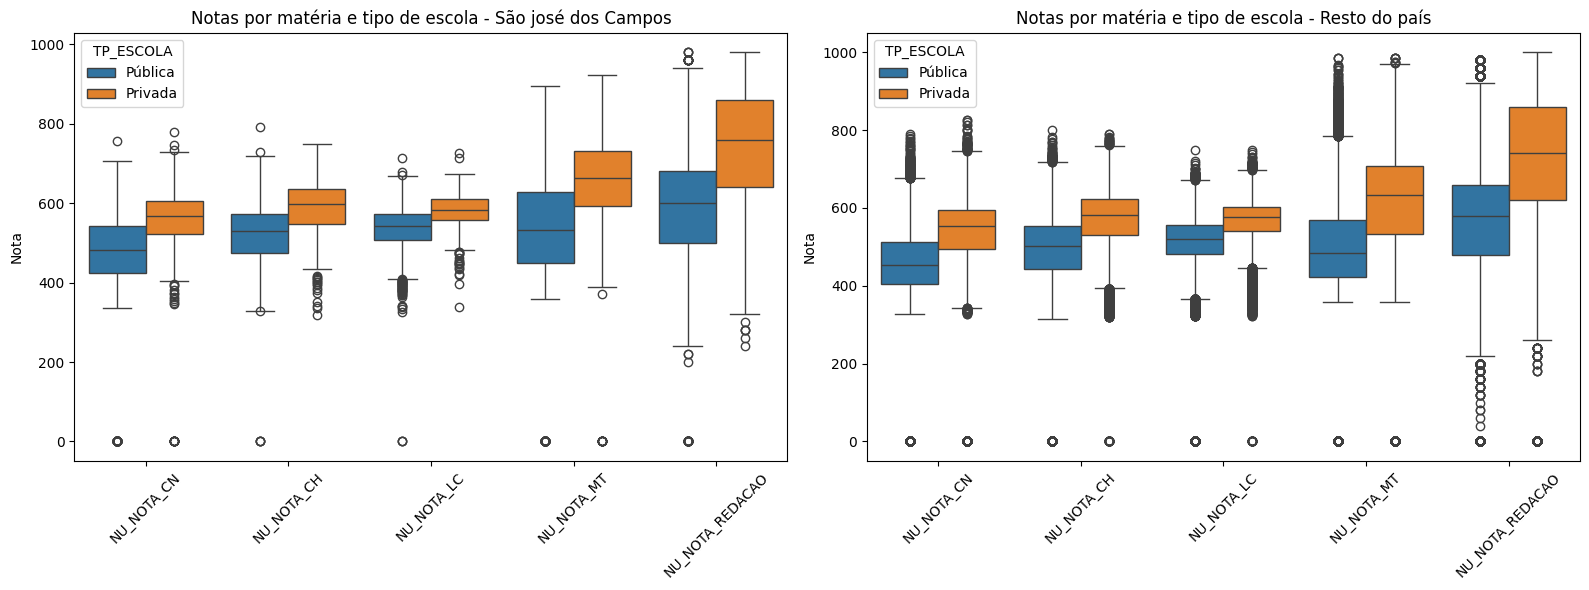

In [354]:
### Organizando os dados para melhor visualização
df_long_sjc = df_sjc_pub_priv.melt(
    id_vars=['TP_ESCOLA'],
    value_vars=notas,
    var_name='Matéria',
    value_name='Nota'
)

# Colocando nomes descritivos para facilitar a visualização e entedimento
df_long_sjc['TP_ESCOLA'] = df_long_sjc['TP_ESCOLA'].replace({2: 'Pública', 3: 'Privada'})

### Organizando os dados para melhor visualização
df_long_brasil = df_brasil_pub_priv.melt(
    id_vars=['TP_ESCOLA'],
    value_vars=notas,
    var_name='Matéria',
    value_name='Nota'
)

# Colocando nomes descritivos para facilitar a visualização e entendimento
df_long_brasil['TP_ESCOLA'] = df_long_brasil['TP_ESCOLA'].replace({2: 'Pública', 3: 'Privada'})

### Criando os gráficos
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

sns.boxplot(data=df_long_sjc, x='Matéria', y='Nota', hue='TP_ESCOLA', ax=axes[0])
axes[0].set_title('Notas por matéria e tipo de escola - São josé dos Campos')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=df_long_brasil, x='Matéria', y='Nota', hue='TP_ESCOLA')
axes[1].set_title('Notas por matéria e tipo de escola - Resto do país')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


In [355]:
# Comparando desempenho escolas PÚBLICAS por matéria
from scipy.stats import mannwhitneyu

for materia in notas:
    # Separando as notas somente dos alunos de escola pública
    notas_sjc = df_sjc_pub_priv[df_sjc_pub_priv['TP_ESCOLA'] == 2][materia]
    notas_brasil = df_brasil_pub_priv[df_brasil_pub_priv['TP_ESCOLA'] == 2][materia]
    
    stat, p = mannwhitneyu(notas_sjc, notas_brasil, alternative='less')
    
    if p <= 0.05:
        print(f"{materia}: desempenho significativamente pior em SJC  (p = {p})")
    else:
        print(f"{materia}: sem diferença significativamente pior (p = {p})")

NU_NOTA_CN: sem diferença significativamente pior (p = 1.0)
NU_NOTA_CH: sem diferença significativamente pior (p = 1.0)
NU_NOTA_LC: sem diferença significativamente pior (p = 1.0)
NU_NOTA_MT: sem diferença significativamente pior (p = 1.0)
NU_NOTA_REDACAO: sem diferença significativamente pior (p = 0.9999999983195139)


<div class="alert alert-primary">
<b>4.1</b> - Explique os resultados obtidos.
</div>

- **Quem se saiu melhor: alunos das escolas de ensino médio públicas ou privadas?** <br>
R = Segundo os boxplots gerados para São José dos Campos, podemos concluir que os alunos das escolas privadas se
saíram melhor, já que em todas as matérias as notas dos alunos de escola privada se concentram acima das notas
dos alunos de escola pública(quer dizer que as notas dos alunos de escola privada em sua maioria são maiores
que as dos alunos de escola pública).<br>

- **O mesmo se observa para o resto do país?**<br>
R = Sim. Ao repetir a análise para o resto do país, observou-se o mesmo padrão de distribuição: em todas as 
matérias as notas dos alunos de escola privada se concentram acima das dos alunos de escola pública.<br>

- **Para que provas, o desempenho das escolas públicas da sua cidade de interesse é significativamente pior (confiança de 95%) que a observada nas escolas do resto do país?**<br>
R = Após aplicar o teste estatístico sugerido, não foram encontradas evidências estatísticas suficientes
para afirmar que, em qualquer das matérias analisadas, os alunos das escolas públicas de São José dos
Campos tiveram desempenho significativamente inferior ao dos alunos das escolas públicas do restante
do país, considerando um nível de confiança de 95%.


<div class="alert alert-info">
<b>5</b> - Como se comparam os inscritos que fizeram a prova com intuito de apenas treinar seus conhecimentos com os demais? E o que se observa para o resto do país? Finalmente, para que provas de sua cidade de interesse, o desempenho dos alunos treinando é significativamente melhor (confiança de 95%) que o dos alunos fazendo a prova para valer? Novamente considere as distribuições de notas, mas desta vez use gráficos de violino e avalie diferenças de notas com o teste T de Student. 
</div> 

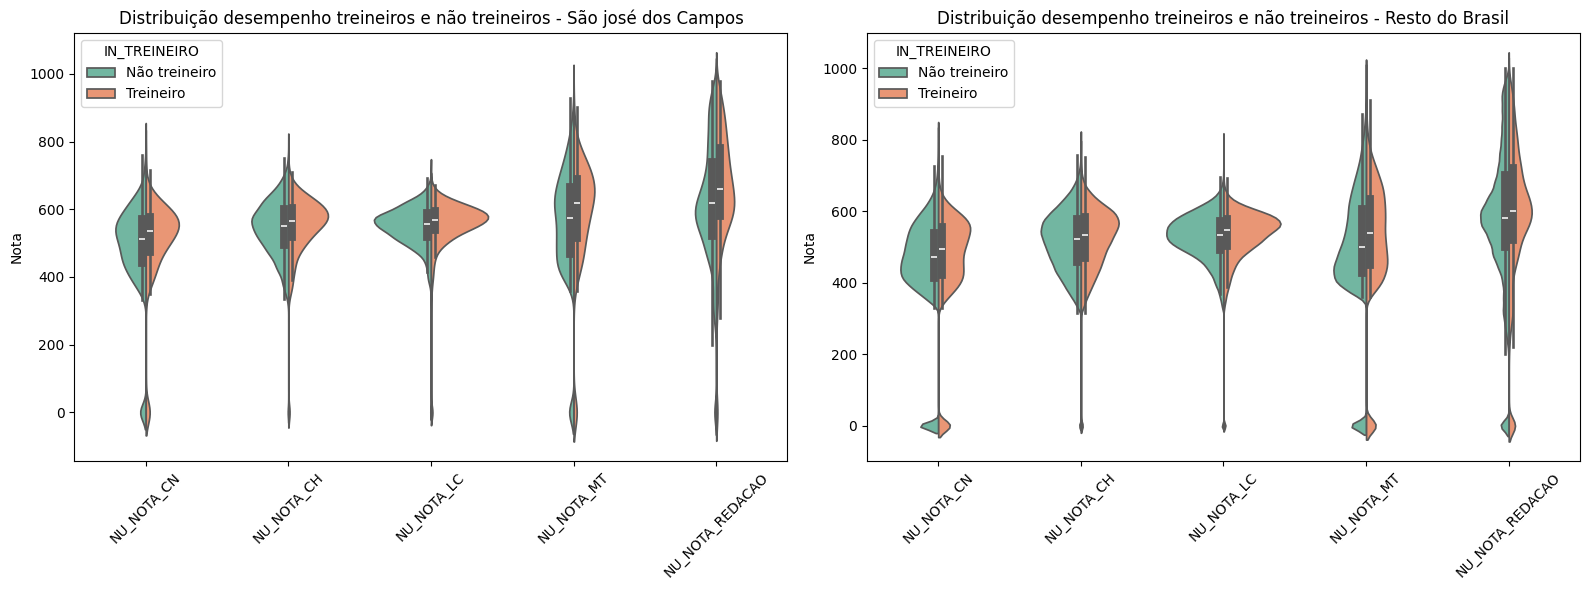

In [356]:
### Organizando os dados para melhor visualização

# Seleciona o municipio São josé dos campos
df_long_sjc = df_enem[cidade_sjc].melt(
    id_vars=['IN_TREINEIRO'],
    value_vars=notas,
    var_name='Matéria',
    value_name='Nota'
)

# Seleciona o resto do país
df_long_brasil = df_enem[resto_brasil].melt(
    id_vars=['IN_TREINEIRO'],
    value_vars=notas,
    var_name='Matéria',
    value_name='Nota'
)

# Colocando nomes descritivos para facilitar a visualização e entendimento
df_long_sjc['IN_TREINEIRO'] = df_long_sjc['IN_TREINEIRO'].replace({0: 'Não treineiro', 1: 'Treineiro'})
df_long_brasil['IN_TREINEIRO'] = df_long_brasil['IN_TREINEIRO'].replace({0: 'Não treineiro', 1: 'Treineiro'})

### Criando os gráficos
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# Gráfico para São José dos Campos
sns.violinplot(data=df_long_sjc, x='Matéria', y='Nota', hue='IN_TREINEIRO', split=True, inner='box', palette='Set2', ax=axes[0])
axes[0].set_title('Distribuição desempenho treineiros e não treineiros - São josé dos Campos')
axes[0].set_xlabel('')
axes[0].tick_params(axis='x', rotation=45)

# Gráfico para o Resto do Brasil
sns.violinplot(data=df_long_brasil, x='Matéria', y='Nota', hue='IN_TREINEIRO', split=True, inner='box', palette='Set2', ax=axes[1])
axes[1].set_title('Distribuição desempenho treineiros e não treineiros - Resto do Brasil')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [357]:
# Selecionando alunos treineiros e não treineiros de todos os tipos de escola
df_treineiros = df_enem[df_enem['IN_TREINEIRO'] == 1]
df_nao_treineiros = df_enem[df_enem['IN_TREINEIRO'] == 0]

# Comparando desempenho escolas PÚBLICAS por matéria
from scipy.stats import ttest_ind

for materia in notas:
    # Separando as notas da matéria específica
    notas_treineiros = df_treineiros[materia]
    notas_nao_treineiros = df_nao_treineiros[materia]

    # Aplicando o teste T de Student
    t_stat, p_valor_bilateral = ttest_ind(notas_treineiros, notas_nao_treineiros, equal_var=False)

    # Convertendo o resultado para unicaudal
    if t_stat > 0:
        p_valor_unicaudal = p_valor_bilateral / 2
    else:
        p_valor_unicaudal = 1 - (p_valor_bilateral / 2)

    # Interpretando o resultado
    if p_valor_unicaudal <= 0.05:
        print(f"{materia}: desempenho significativamente melhor entre treineiros em SJC (p = {p_valor_unicaudal}")
    else:
        print(f"{materia}: sem evidência de desempenho significativamente melhor entre treineiros em SJC (p = {p_valor_unicaudal})")

NU_NOTA_CN: desempenho significativamente melhor entre treineiros em SJC (p = 7.260304599754262e-21
NU_NOTA_CH: desempenho significativamente melhor entre treineiros em SJC (p = 8.149799776087886e-54
NU_NOTA_LC: desempenho significativamente melhor entre treineiros em SJC (p = 5.925804070085506e-102
NU_NOTA_MT: desempenho significativamente melhor entre treineiros em SJC (p = 1.0287572143295136e-130
NU_NOTA_REDACAO: desempenho significativamente melhor entre treineiros em SJC (p = 2.3855087892621678e-22


<div class="alert alert-primary">
<b>5.1</b> - Explique os resultados obtidos.
</div>

- **Como se comparam os inscritos que fizeram a prova com intuito de apenas treinar seus conhecimentos com os demais?** <br>
R = De acordo com o gráfico gerado, no município de São José dos Campos, observa-se que as medianas e a concentração das notas dos alunos treineiros estão, em geral, acima das dos não treineiros. Isso indica que os treineiros, em média, tiveram desempenho superior.

- **O que se observa para o resto do país?**<br>
R = Com base nos gráficos e testes realizados, observa-se que no restante do país o padrão se repete: os treineiros tendem a apresentar desempenho superior aos não treineiros, com quartis e medianas geralmente mais elevados.

- **Para que provas de sua cidade de interesse, o desempenho dos alunos treinando é significativamente melhor (confiança de 95%) que o dos alunos fazendo a prova para valer?** <br>
R = Após a aplicação do teste T de Student unicaudal, verificou-se que, em São José dos Campos, os alunos treineiros apresentaram desempenho significativamente superior aos não treineiros em todas as áreas avaliadas, com 95% de confiança.

<div class="alert alert-info">
<b>6</b> - Sobre a redação, como se comparam os desempenhos dos inscritos conforme o ano de conclusão do ensino médio em sua cidade de interesse? E no resto do país? Usando um gráfico de linhas, trace as notas médias obtidas contra o ano de conclusão.<br><i>ATENÇÃO</i>: Em `TP_ANO_CONCLUIU`, defina 2019 para todas as intâncias onde `TP_ST_CONCLUSAO` seja igual a 2 (2 = "Estou cursando e concluirei o Ensino Médio em 2019").
</div> 

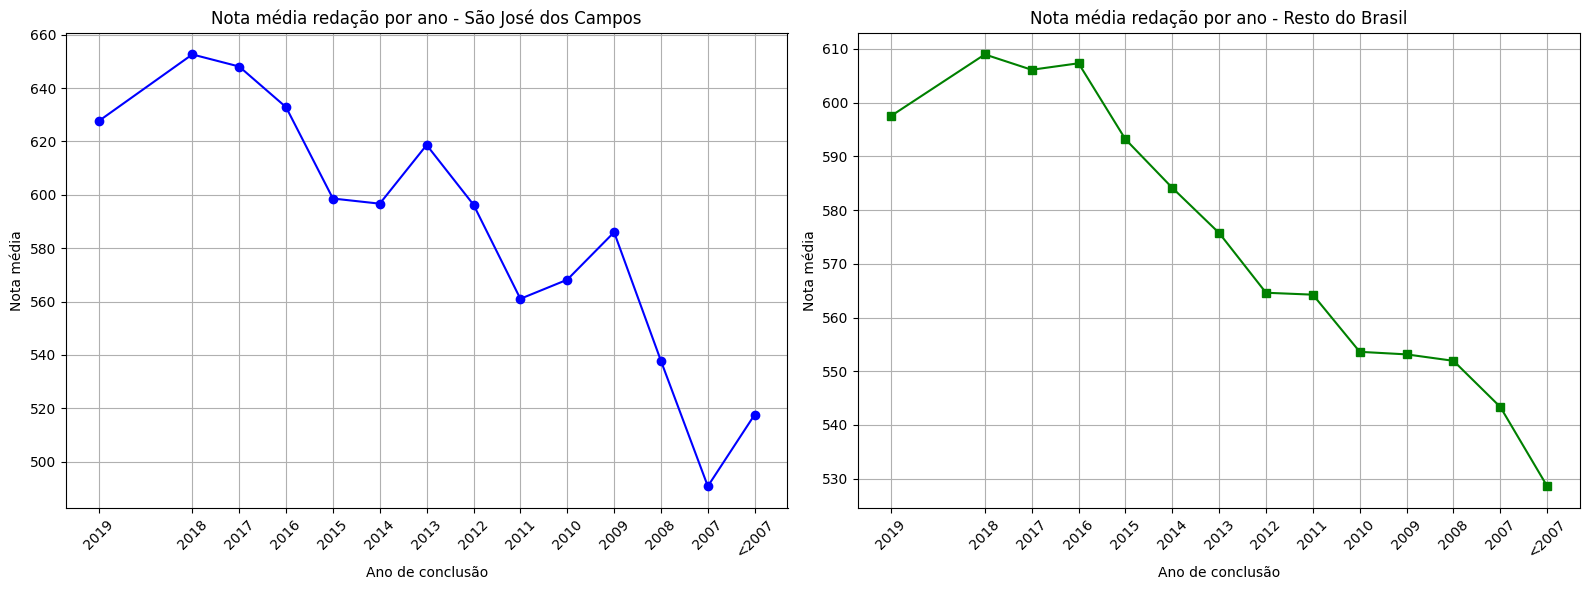

In [ ]:
finalistas = df_enem['TP_ST_CONCLUSAO'] == 2

# IMPORTANTE! Para melhor visualizacão do grafico foi preciso fzr ajustes no 'TP_ANO_CONCLUIU' já que
# colocar 2019 diretamente como pedido no enunciado afeta a lógica da categoria
# CONSULTAR O DICIONÁRIO QUAISQUER DÚVIDAS

df_enem.loc[finalistas & (df_enem['TP_ANO_CONCLUIU'] == 0), 'TP_ANO_CONCLUIU'] = -1

# EXCLUSÃO DOS CASOS "NÃO INFORMADO" do gráfico:
# Os registros com TP_ANO_CONCLUIU == 0 representam alunos que não informaram o ano de conclusão do ensino médio.
# Como esses valores não correspondem a uma faixa temporal real, foram excluídos da análise gráfica para evitar distorções na escala e facilitar a interpretação.
# Essa exclusão não altera os dados originais e é apenas uma decisão visual para melhorar a clareza do gráfico.

media_sjc = df_enem[cidade_sjc & (df_enem['TP_ANO_CONCLUIU'] != 0)].groupby('TP_ANO_CONCLUIU')['NU_NOTA_REDACAO'].mean()
media_brasil = df_enem[resto_brasil & (df_enem['TP_ANO_CONCLUIU'] != 0)].groupby('TP_ANO_CONCLUIU')['NU_NOTA_REDACAO'].mean()

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

anos_conclusao = {
    -1: '2019',
    0: 'Não informado',
    1: '2018',
    2: '2017',
    3: '2016',
    4: '2015',
    5: '2014', 
    6: '2013',
    7: '2012',
    8: '2011',
    9: '2010',
    10: '2009',
    11: '2008',
    12: '2007',
    13: '<2007'
}

# Gráfico para São José dos Campos
axes[0].plot(media_sjc.index, media_sjc.values, marker='o', color='blue')
axes[0].set_xticks(media_sjc.index)
axes[0].set_xticklabels([anos_conclusao.get(i, str(i)) for i in media_sjc.index], rotation=45)

axes[0].set_title('Nota média redação por ano - São José dos Campos')
axes[0].set_xlabel('Ano de conclusão')
axes[0].set_ylabel('Nota média')
axes[0].grid(True)

# Gráfico para Resto do Brasil
axes[1].plot(media_brasil.index, media_brasil.values, marker='s', color='green')
axes[1].set_xticks(media_brasil.index)
axes[1].set_xticklabels([anos_conclusao.get(i, str(i)) for i in media_brasil.index], rotation=45)

axes[1].set_title('Nota média redação por ano - Resto do Brasil')
axes[1].set_xlabel('Ano de conclusão')
axes[1].set_ylabel('Nota média')
axes[1].grid(True)

plt.tight_layout()
plt.show()

<div class="alert alert-primary">
<b>6.1</b> - Explique os resultados obtidos.
</div>

- **Sobre a redação, como se comparam os desempenhos dos inscritos conforme o ano de conclusão do ensino médio em sua cidade de interesse?**<br>
R = Com base no gráfico, pode-se afirmar que com o passar dos anos houve a tendência do aumento da média das notas da proda de redação em São José dos Campos. Vale ressaltar que no ano de 2019 houve uma queda na média das notas quando comparada com os anos anteriores.

- **E no resto do país?**<br>
R = No resto do pais observa-se a mesma tendência, porém a média das notas sofrem um aumento mais constante, onde com o passar dos anos a maioria cresce continuamente, comm exceção do ano de 2019 onde também houve um aqueda na média das notas no resto do país.

<div class="alert alert-info">
    <b>7</b> - Qual a relação entre o grau de instrução dos pais (<code>Q001</code> e <code>Q002</code>) e o desempenho dos seus filhos, tanto na sua cidade de interesse quanto no resto do país? Considere a média de todas as notas do candidato como seu desempenho. 
</div> 

<div class="alert alert-primary">
<b>7.1</b> - Explique os resultados obtidos.
</div>

**Ainda considerando o desempenho calculado na questão anterior e, agora, as seguintes faixas de renda (`Q006`):**

A = Nenhuma renda.<br/>B = Até R\\$ 998,00.<br/>C = De R\\$ 998,01 até R\\$ 1.497,00.<br/>D = De R\\$ 1.497,01 até R\\$ 1.996,00.<br/>E = De R\\$ 1.996,01 até R\\$ 2.495,00.<br/>F = De R\\$ 2.495,01 até R\\$ 2.994,00.<br/>G = De R\\$ 2.994,01 até R\\$ 3.992,00.<br/>H = De R\\$ 3.992,01 até R\\$ 4.990,00.<br/>I = De R\\$ 4.990,01 até R\\$ 5.988,00.<br/>J = De R\\$ 5.988,01 até R\\$ 6.986,00.<br/>K = De R\\$ 6.986,01 até R\\$ 7.984,00.<br/>L = De R\\$ 7.984,01 até R\\$ 8.982,00.<br/>M = De R\\$ 8.982,01 até R\\$ 9.980,00.<br/>N = De R\\$ 9.980,01 até R\\$ 11.976,00.<br/>O = De R\\$ 11.976,01 até R\\$ 14.970,00.<br/>P = De R\\$ 14.970,01 até R\\$ 19.960,00.<br/>Q = Mais de R\\$ 19.960,00.<br/>

Responda:

<div class="alert alert-info">
<b>8</b> - É possível afirmar que, dos inscritos que concluem o ensino médio em 2019, os mais ricos são os que obtém o maior desempenho, tanto na sua cidade de interesse quanto no resto do país? Neste caso, além de uma inspeção visual, prove sua afirmação usando um teste de correlação de Spearman.
</div>

<div class="alert alert-primary">
<b>8.1</b> - Explique os resultados obtidos.
</div>

<div class="alert alert-info">
    <b>9</b> - Qual a nota geral média dos alunos, de acordo com o tipo de estado civil (<code>TP_ESTADO_CIVIL</code>), tanto em sua cidade de interesse quanto no resto do país?
</div>


<div class="alert alert-primary">
<b>9.1</b> - Explique os resultados obtidos.
</div>

<div class="alert alert-info">
    <b>10</b> - Qual a nota geral média dos alunos, de acordo com o tipo da lingua estrangeira escolhida (<code>TP_LINGUA</code>) tanto em sua cidade de interesse quanto no resto do país?
</div>

<div class="alert alert-primary">
<b>10.1</b> - Explique os resultados obtidos.
</div>

<div class="alert alert-info">
    <b>11</b> - Qual a nota geral média dos alunos, de acordo com ocupação dos pais/responsáveis e (<code>Q003</code> e <code>Q004</code>) tanto em sua cidade de interesse quanto no resto do país?
</div>

<div class="alert alert-primary">
<b>11.1</b> - Explique os resultados obtidos.
</div>

----
#### Transformação e Engenharia de atributos

<div class="alert alert-info">
    <b>12</b> - A partir do campo <code>NU_IDADE</code>, que armazena a idade dos inscritos, crie a coluna <code>FAIXA_ETARIA</code> com os seguintes intervalos:
    <ul>
        <li>[10..18)</li>
        <li>[18..22)</li>
        <li>[22..26)</li>
        <li>[26..33)</li>
        <li>[33..40)</li>
        <li>[40..55)</li>
        <li>[55..65)</li>
        <li>[65..70)</li>
        <li>[70..100]</li>
    </ul><i>ATENÇÃO</i>: Apague instâncias com idade inferior a 10 ou superior a 100 anos.
</div>

Considerando apenas os alunos que não faltaram a nenhuma prova (`TP_PRESENCA_**`), queremos tentar prever se um dado inscrito irá obter uma nota de redação acima ou abaixo da média, a partir das seguintes informações:

- `FAIXA_ETARIA`, `NO_MUNICIPIO_RESIDENCIA`, `TP_SEXO`, `TP_ESTADO_CIVIL`, `TP_ST_CONCLUSAO`, `TP_ANO_CONCLUIU`, `TP_ESCOLA`
- `CO_PROVA_CH`,`CO_PROVA_LC`, `NU_NOTA_CH`, `NU_NOTA_LC`, `TP_LINGUA`
- `Q001`, `Q002`, `Q003`, `Q004`, `Q005`, `Q006`, `Q021`, `Q022`, `Q024`, `Q025`
- `TARGET` 

<div class="alert alert-info">
<b>13</b> - Prepare os dados para aprendizado, convertendo strings para dados categóricos, mantendo sem mudanças os dados categóricos não numéricos e padronizando dados numéricos usando Z-score.<br><i>ATENÇÃO</i>: Você deve criar a coluna `TARGET` para ser utilizada como alvo de classificação e avaliação de atributos. Ela deve ser `1`, caso a nota da redação do aluno seja maior que a média, ou `0`, caso contrário.
</div>

<div class="alert alert-info">
<b>14</b> - Que atributos são os mais importantes considerando correlação absoluta com o alvo, ANOVA, chi quadrado, Informação Mútua e a importância das variáveis de acordo com uma floresta aleatória? Considere apenas candidatos em sua cidade de interesse.<br><i>Dica</i>: Para facilitar a visualização, coloque todas as métricas em um único dataframe. Então as normalize para que todas fiquem entre 0 e 1. Obtenha então uma média agregada das métricas normalizadas e use esta média agregada para ordenar as variáveis da mais à menos importante. 
</div>